In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("ab_testing.csv")

In [5]:
df.head()

,User ID,Group,Page Views,Time Spent,Conversion,Device,Location
0,14292,B,3,424,No,Mobile,Northern Ireland
1,11682,A,9,342,No,Mobile,Scotland
2,19825,A,2,396,No,Desktop,Northern Ireland
3,16080,B,4,318,No,Desktop,Wales
4,18851,A,1,338,Yes,Desktop,Scotland


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   User ID     5000 non-null   int64 
 1   Group       5000 non-null   object
 2   Page Views  5000 non-null   int64 
 3   Time Spent  5000 non-null   int64 
 4   Conversion  5000 non-null   object
 5   Device      5000 non-null   object
 6   Location    5000 non-null   object
dtypes: int64(3), object(4)
memory usage: 273.6+ KB


In [7]:
df.shape

(5000, 7)

In [8]:
df.isnull().sum()

User ID       0
Group         0
Page Views    0
Time Spent    0
Conversion    0
Device        0
Location      0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Group'].unique()

array(['B', 'A'], dtype=object)

In [11]:
df['Conversion'].unique()

array(['No', 'Yes'], dtype=object)

In [12]:
df['Location'].unique()

array(['Northern Ireland', 'Scotland', 'Wales', 'England'], dtype=object)

In [13]:
df.describe()

,User ID,Page Views,Time Spent
count,5000.000000,5000.000000,5000.000000
mean,14925.159000,7.537600,242.512600
std,2869.153773,4.022465,118.254153
min,10001.000000,1.000000,40.000000
25%,12456.250000,4.000000,137.000000
50%,14858.500000,8.000000,243.000000
75%,17379.750000,11.000000,346.000000
max,19995.000000,14.000000,449.000000


In [14]:
df['Group'].value_counts()

Group
A    2519
B    2481
Name: count, dtype: int64

In [15]:
df['Group'].value_counts(normalize=True) * 100

Group
A    50.38
B    49.62
Name: proportion, dtype: float64

In [16]:
df['Conversion'].value_counts()

Conversion
No     4515
Yes     485
Name: count, dtype: int64

In [17]:
pd.crosstab(df['Group'], df['Conversion'])

Conversion,No,Yes
Group,,
A,2383,136
B,2132,349


In [18]:
conversions = df[df['Conversion'] == 'Yes']['Group'].value_counts()

print(conversions)

Group
B    349
A    136
Name: count, dtype: int64


In [23]:
# Count total users in each group
total_users = df['Group'].value_counts()

# Count successful conversions
conversions = df[df['Conversion'] == 'Yes']['Group'].value_counts()

# Calculate conversion rate
conversion_rate = (conversions / total_users) * 100

print(conversion_rate)

Group
A     5.398968
B    14.066909
Name: count, dtype: float64


In [24]:
print(df.columns)

Index(['User ID', 'Group', 'Page Views', 'Time Spent', 'Conversion', 'Device',
       'Location'],
      dtype='object')


In [25]:
alpha = 0.05

print("Significance Level:", alpha)

Significance Level: 0.05


In [26]:
from statsmodels.stats.proportion import proportions_ztest

In [27]:
!pip install statsmodels

In [28]:
success_A = 136
success_B = 349

total_A = 2519
total_B = 2481

counts = [success_A, success_B]
nobs = [total_A, total_B]

z_stat, p_value = proportions_ztest(
    counts,
    nobs,
    alternative='two-sided'
)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -10.354488520266216
P-value: 3.9931511894201938e-25


In [29]:
if p_value < alpha:
    print("Reject Null Hypothesis")
    print("There is a significant difference between Group A and Group B")
else:
    print("Fail to Reject Null Hypothesis")
    print("There is no sufficient evidence of a significant difference")

Reject Null Hypothesis
There is a significant difference between Group A and Group B


In [30]:
from statsmodels.stats.proportion import confint_proportions_2indep

In [31]:
lower, upper = confint_proportions_2indep(
    success_B,
    total_B,
    success_A,
    total_A,
    method='newcomb',
    alpha=0.05
)

print("Lower Limit:", lower)
print("Upper Limit:", upper)

Lower Limit: 0.07046212908296373
Upper Limit: 0.1030920247819473


In [32]:
print("Lower Limit:", lower * 100, "%")
print("Upper Limit:", upper * 100, "%")

Lower Limit: 7.046212908296373 %
Upper Limit: 10.309202478194731 %


In [33]:
rate_A = conversion_rate['A']
rate_B = conversion_rate['B']

relative_lift = ((rate_B - rate_A) / rate_A) * 100

print("Relative Lift:", relative_lift, "%")

Relative Lift: 160.54810678805987 %


In [34]:
summary = pd.DataFrame({
    'Metric': ['Total Users', 'Conversions', 'Non-conversions', 'Conversion Rate'],
    'Group A': [total_A, success_A, total_A - success_A, rate_A],
    'Group B': [total_B, success_B, total_B - success_B, rate_B]
})

summary

,Metric,Group A,Group B
0,Total Users,2519.000000,2481.000000
1,Conversions,136.000000,349.000000
2,Non-conversions,2383.000000,2132.000000
3,Conversion Rate,5.398968,14.066909


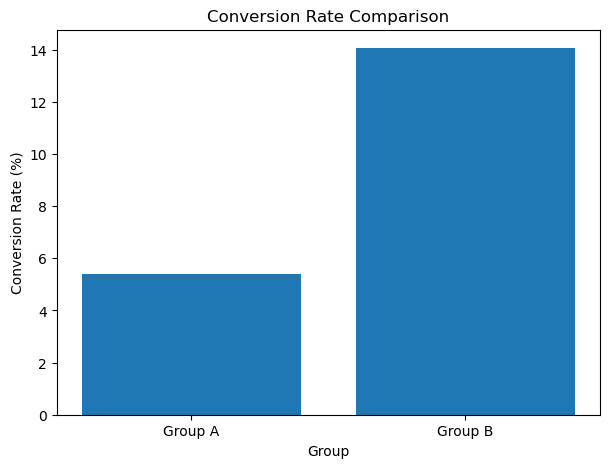

In [35]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Group A', 'Group B'],
    [rate_A, rate_B]
)

plt.title('Conversion Rate Comparison')
plt.xlabel('Group')
plt.ylabel('Conversion Rate (%)')

plt.show()